## Task 1: Build a RFM table 

In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, accuracy_score)
from sklearn.base import clone

In [2]:
orders = pd.read_csv(r"C:\Users\DARLING\Desktop\AI ML Notes\Instamart_project\data\clean\orders.csv")

# Completed orders only
orders["order_ts"] = pd.to_datetime(orders["order_ts"])
completed_status = orders[orders["status"].str.strip().str.lower() == "completed"]

snapshot = pd.Timestamp("2025-10-01 00:00:00")

# One row per customer
rfm = (
    completed_status.groupby("customer_id")
        .agg(last_order_ts=("order_ts", "max"),
             frequency=("order_id", "nunique"),
             monetary=("order_amount", "sum"))
        .reset_index()
)

# Recency = whole days between snapshot and last completed order
rfm["recency"] = (snapshot - rfm["last_order_ts"]).dt.days

rfm = rfm[["customer_id", "recency", "frequency", "monetary"]]

print("Total Customers:", len(rfm))
print("Recency -> median:", rfm["recency"].median(), "| min:", rfm["recency"].min(),"| max:", rfm["recency"].max())
print("Frequency -> mean:", round(rfm["frequency"].mean(), 2), "| max:", rfm["frequency"].max())
print("Monetary -> mean:", round(rfm["monetary"].mean(), 2),"| max:", round(rfm["monetary"].max(), 2))
print("--------------------------------------------------")
print(rfm.head())


Total Customers: 1175
Recency -> median: 19.0 | min: 0 | max: 180
Frequency -> mean: 9.46 | max: 33
Monetary -> mean: 2552.06 | max: 14766.55
--------------------------------------------------
  customer_id  recency  frequency  monetary
0       C0001       14          4    512.85
1       C0002       28          7   4644.90
2       C0003        7         22   3644.85
3       C0004        0          5    369.00
4       C0005      147          2    324.00


## How to read the segments.
1. RECENCY   -   How recently did they order or how many days ago?                    Low is better
2. FREQUENCY -   How often do they order or total number of completed orders?         High is better
3. MONETARY  -   How much have they spent in total include all the completed order?   High is better

## Task 2: Customer Sgmentation using K - Mean Clustering
### Standardise and Fit_Transform
    1. First scale the document 'only 3 RFM columns' with Standard Scalar
    2. Fit and Transform a K-Mean model with scaled output with parameter ( k = 2 to 8, n_init = 10)
    

In [3]:
# Standardise the three RFM columns
X = rfm[["recency", "frequency", "monetary"]]
X_scaled = StandardScaler().fit_transform(X)

# Fit K-means for K = 2 to 8, record inertia and silhouette
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    results.append({
        "K": k,
        "inertia": round(km.inertia_, 1),
        "silhouette": round(silhouette_score(X_scaled, labels), 3),
    })

k_table = pd.DataFrame(results)
print(k_table)


   K  inertia  silhouette
0  2   1820.8       0.465
1  3   1268.2       0.445
2  4    743.1       0.526
3  5    617.4       0.480
4  6    503.2       0.482
5  7    408.5       0.416
6  8    366.5       0.412


### HIGH 'K' VALUE == LOW INERTIA:
Inertia value always decreases when K value increases.
Because the inertia is some of squared distance between points to their centroid.
When we add more clusters, there will more centroids and there will be decrease in distance between points to their centroid

    As per Elbow plot, we can say K = 4 have a Elbow corner. And Silhouette Score is '0.526' which is the maximum value good to have.
    
    Total number of customers in Cluster 0: 436
    Total number of customers in Cluster 1: 138
    Total number of customers in Cluster 2: 419
    Total number of customers in Cluster 3: 182

## Overall Observersion 
Cluster - 0	 
Low frequency (1-5 orders), low spend (90-513), fairly recent (0-61 days)	
New or occasional low-value customers.

Cluster - 1	
High monetary (4,645-8,425), medium frequency (5-11), recent (8-28 days)	
Premium: few orders, big baskets.

Cluster - 2	
Very high frequency (15-22 orders), very recent (3-11 days), medium-to-high 
spend (2,600-4,258)	Loyal, frequent customers.

Cluster - 3	
High recency (66-147 days, so inactive for a long time), low frequency (2-4)	
At-risk or lapsing customers

## Elbow plot and silhouette plot

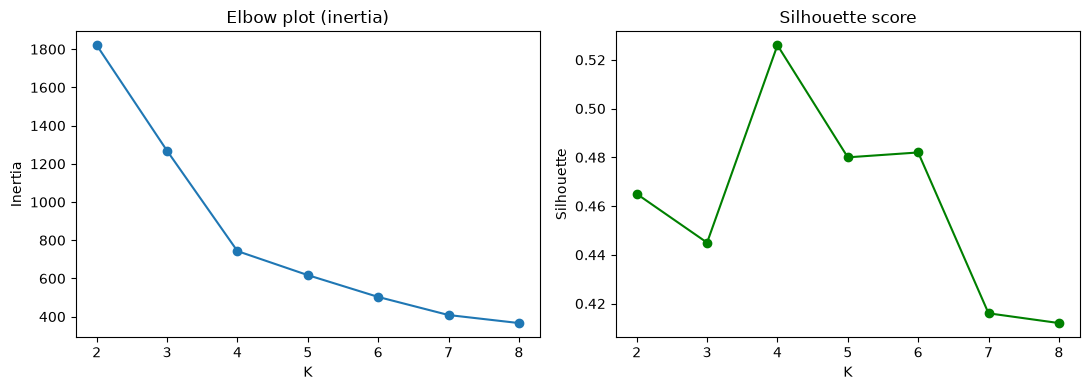

K = 4 is a good choice based on the elbow point and silhouette score.
K = 2 when interia is 1820.8 and K = 8 when inertia is 366.5

-----------------------------------
HIGH 'K' VALUE == LOW INERTIA:
-----------------------------------
Inertia value always decreases when K value increases.
Because the inertia is some of squared distance between points to their centroid.
When we add more clusters, there will more centroids and there will be decrease in distance between points to their centroid.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_table["K"], k_table["inertia"], marker="o")
ax[0].set_title("Elbow plot (inertia)")
ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia")

ax[1].plot(k_table["K"], k_table["silhouette"], marker="o", color="green")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

print("K = 4 is a good choice based on the elbow point and silhouette score.")
print("K = 2 when interia is 1820.8 and K = 8 when inertia is 366.5")
print(f"\n{'-'*35}\nHIGH 'K' VALUE == LOW INERTIA:\n{'-'*35}")
print("Inertia value always decreases when K value increases.")
print("Because the inertia is some of squared distance between points to their centroid.")
print("When we add more clusters, there will more centroids and there will be decrease in distance between points to their centroid.")

## K-means segments in RFM space


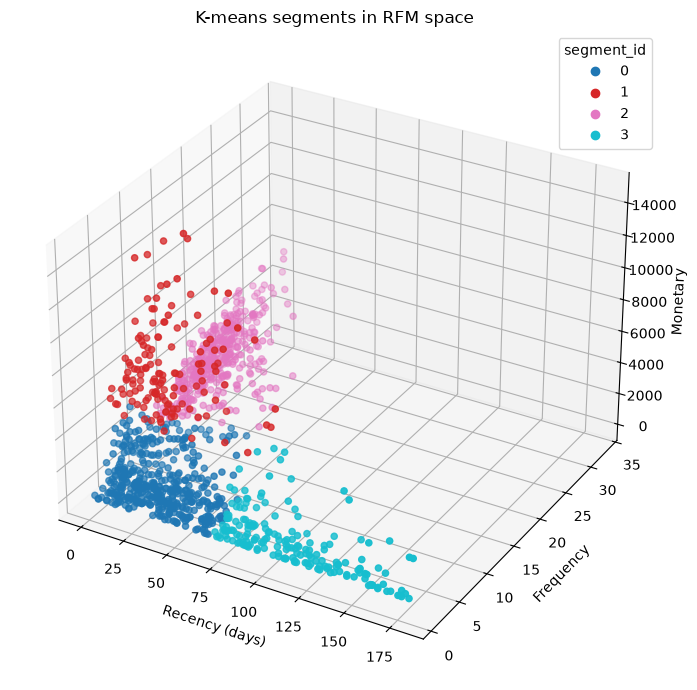

In [5]:
final_k = 4
km_final = KMeans(n_clusters=final_k, n_init=10, random_state=42)
rfm["segment_id"] = km_final.fit_predict(X_scaled)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(rfm["recency"], rfm["frequency"], rfm["monetary"],
                     c=rfm["segment_id"], cmap="tab10", s=20)

ax.set_xlabel("Recency (days)")
ax.set_ylabel("Frequency")
ax.set_zlabel("Monetary")
ax.set_title("K-means segments in RFM space")
ax.legend(*scatter.legend_elements(), title="segment_id")
plt.tight_layout()
plt.show()

## Task 3 : PCA projection

In [6]:
#(a) Size and mean RFM per segment
final_k = 4
km_final = KMeans(n_clusters=final_k, n_init=10, random_state=42)
rfm["segment_id"] = km_final.fit_predict(X_scaled)

profile = (
    rfm.groupby("segment_id")
       .agg(size=("customer_id", "count"),
            mean_recency=("recency", "mean"),
            mean_frequency=("frequency", "mean"),
            mean_monetary=("monetary", "mean"))
       .round(2)
)
#Name the segments, add action and mark Premium
premium_id = profile["mean_monetary"].idxmax()
print("Premium segment_id:", premium_id)

segment_names = {
    0: "Occasional Low-Spenders",
    1: "Premium Big-Basket Customers",
    2: "Loyal Frequent Customers",
    3: "At-Risk / Lapsing Customers",
}

segment_actions = {
    0: "Send welcome offers and nudges to raise order frequency",
    1: "Offer VIP perks and early access to retain high-value spend",
    2: "Run a loyalty/rewards programme to keep ordering habits",
    3: "Send win-back discounts before they churn completely",
}

rfm["segment_name"] = rfm["segment_id"].map(segment_names)
rfm["is_premium"]   = (rfm["segment_id"] == premium_id).astype(int)

summary = profile.copy()
summary["segment_name"] = summary.index.map(segment_names)
summary["action"]       = summary.index.map(segment_actions)
summary["is_premium"]   = (summary.index == premium_id)
print(summary.to_string())

# (c) PCA projection
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

print("explained_variance_ratio_:", pca.explained_variance_ratio_.round(3))
print("Total:", pca.explained_variance_ratio_.sum().round(3))

evr = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained variance ratio": pca.explained_variance_ratio_,
    "Cumulative ratio": np.cumsum(pca.explained_variance_ratio_),
}).round(3)
print(evr.to_string(index=False))

os.makedirs("outputs", exist_ok=True)

out = rfm[["customer_id", "recency", "frequency", "monetary",
           "segment_id", "segment_name", "is_premium"]]
out.to_csv("outputs/customer_segments.csv", index=False)

print(out.shape)
print(out.head())

Premium segment_id: 1
            size  mean_recency  mean_frequency  mean_monetary                  segment_name                                                       action  is_premium
segment_id                                                                                                                                                          
0            436         28.86            3.77        1057.62       Occasional Low-Spenders      Send welcome offers and nudges to raise order frequency       False
1            138         24.12            6.77        7129.70  Premium Big-Basket Customers  Offer VIP perks and early access to retain high-value spend        True
2            419          8.77           19.40        3410.02      Loyal Frequent Customers      Run a loyalty/rewards programme to keep ordering habits       False
3            182        109.04            2.20         685.99   At-Risk / Lapsing Customers         Send win-back discounts before they churn completely 

In [7]:
pca_df = pd.DataFrame(pcs, columns=["PC1", "PC2"])
pca_df.insert(0, "customer_id", rfm["customer_id"].values)
pca_df["segment_id"] = rfm["segment_id"].values

print(pca_df.shape)          # (1175, 4)
print(pca_df.head(5).round(3))

(1175, 4)
  customer_id    PC1    PC2  segment_id
0       C0001 -0.581 -0.845           0
1       C0002  0.368  0.705           1
2       C0003  1.610 -0.306           2
3       C0004 -0.325 -1.117           0
4       C0005 -2.793  1.013           3


## Step - by - Step process
(a) Size and mean RFM per segment
(b) Name the segments and mark Premium 
Premium segment_id: 1
It is confirmed that:
The 138-customer segment has mean monetary = 7129.70, mean frequency = 6.77; 
The 419-customer segment has mean frequency = 19.4 and mean recency about 8.77 days. 
(c) Appled PCA(n_components=2) to the scaled RFM matrix and explained_variance_ratio_ (0.852). 

Created outputs/customer_segments.csv with columns customer_id, recency, frequency, monetary, segment_id, segment_name, is_premium.


### Reminder for the reader: 
The cluster numbers 0 to 3 are only labels assigned by K-means and have no ordering, so cluster 3 is not “better” or “worse” than cluster 0.

## Task 4 - Creat a dataset to perform Surpervised Learning

In [8]:
# 1. Load data
orders    = pd.read_csv("data/clean/orders.csv", parse_dates=["order_ts"])
customers = pd.read_csv("data/clean/customers.csv", parse_dates=["signup_date"])
products  = pd.read_csv("data/clean/products.csv")
prod_categoty = "category"

# 2. Add product category to orders
orders = orders.merge(products[["product_id", prod_categoty]].drop_duplicates("product_id"),
                      on="product_id", how="left")
orders["status"] = orders["status"].str.strip().str.lower()

cutoff = pd.Timestamp("2025-09-01")
end    = pd.Timestamp("2025-10-01")

# 3. Orders before cutoff (for features) and September completed orders (for label)
before      = orders[orders["order_ts"] < cutoff]
before_done = before[before["status"] == "completed"]
sept_data  = orders[(orders["order_ts"] >= cutoff) & (orders["order_ts"] < end)
                     & (orders["status"] == "completed")]

# 4. Features
data = before_done.groupby("customer_id").agg(
    last_order=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_amount", "sum"),
    avg_discount_pct=("discount_pct", "mean"),
    avg_delivery_minutes=("delivery_minutes", "mean"),
    favourite_category=(prod_categoty, lambda s: s.mode().iloc[0]),
).reset_index()

data["recency"] = (cutoff - data["last_order"]).dt.days

# Cancellation rate = cancelled / (completed + cancelled), before cutoff
final = before[before["status"].isin(["completed", "cancelled"])]
canc = (final["status"].eq("cancelled")
        .groupby(final["customer_id"]).mean()
        .rename("cancellation_rate").reset_index())
data = data.merge(canc, on="customer_id", how="left")

# Customer attributes and tenure
data = data.merge(customers[["customer_id", "city", "age", "gender", "signup_date"]],
                  on="customer_id", how="left")
data["tenure_days"] = (cutoff - data["signup_date"]).dt.days

# 5. Label: lapsed = 1 if no completed order in September
data["lapsed"] = (~data["customer_id"].isin(sept_data["customer_id"])).astype(int)

print("Cohort:", len(data), "| Lapsed:", data["lapsed"].sum(),
      f"({data['lapsed'].mean():.2%})") 
data.to_csv("outputs/lapse_dataset.csv", index=False)       

# 6. Features / target / split
feature_cols = ["recency", "frequency", "monetary", "avg_discount_pct",
                "cancellation_rate", "avg_delivery_minutes", "favourite_category",
                "city", "age", "gender", "tenure_days"]
X = data[feature_cols]
y = data["lapsed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)  

# 7. Baseline: always predict "not lapsed"
base = np.zeros(len(y_test), dtype=int)
print("Baseline accuracy:", round(accuracy_score(y_test, base)*100, 1)) 
print("Baseline lapsed F1:", f1_score(y_test, base, zero_division=0)) 

Cohort: 1156 | Lapsed: 443 (38.32%)
Train: (924, 11) | Test: (232, 11)
Baseline accuracy: 61.6
Baseline lapsed F1: 0.0


## Creating Features columns (X): 
### Cutoff 2025-09-01 
Which means all the features in the dataset shold use the date befor the cutoff. The dataset is created customer with at least one completed order before the cutoff. 
    *Recency  -----  last completed order before cutoff
    *Frequency ----  completed orders before cutoff
    *Monetary -----  completed orders before cutoff	
    *Avg_discount_pct ----  completed orders before cutoff
    *Avg_delivery_minutes -----  completed orders before cutoff
    *Favourite_category	-----  completed orders before cutoff
    *Cancellation_rate ----- completed and cancelled orders before cutoff (cancelled orders ÷ all orders with a final status)
    *City, *Gender, *Age ----- customers table (not order dates)
    *Tenure_days cutoff minus signup_date ----- Uses the cutoff date, not September orders

## Creating Label/Lapse column (Y):
The label lapsed is created with dataset dated between 2025-09-01 to 2025-09-30
If the customer has no completed order dated between 2025-09-01 to 2025-09-30 = 1 (Lapsed)
If the customer has atleast one completed order dated between 2025-09-01 to 2025-09-30 = 0 (Active)

## Train Test split:
Splited with train_test_split(test_size=0.2, stratify=y, random_state=42)
        Total number of customers  = 1,156;
        Number of Lapsed = 443 (38.32%);
        Baseline model accuracys score = 61.6;
        Baseline model lapsed F1 score = 0.0;
### zero_division=0 
With zero_division=0, in scikit - learn it quietly treats that undefined value as 0, so you get a clean 0.0 and no warning. Without the setting, scikit-learn prints a warning (UndefinedMetricWarning). Because The baseline model made zero lapsed predictions which is Precision = (correct lapsed predictions) ÷ (total lapsed predictions) = 0 ÷ 0, which is undefined.

## Task 5 - Preprocessing Without leakage

In [9]:


# 1. Column groups
nominal_column = ["city", "gender", "favourite_category"]
numeric_column = ["recency", "frequency", "monetary", "avg_discount_pct",
                "cancellation_rate", "avg_delivery_minutes", "age", "tenure_days"]

# 2. Preprocessor: one-hot (k-1 columns) for nominal, standardise numeric
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), nominal_column),
    ("num", StandardScaler(), numeric_column),
])

# 3. Pipeline (a model is added to it in Task 6)
prep_pipe = Pipeline([("prep", preprocessor)])

# 4. Fit on TRAIN only, then only transform the test rows
X_train_p = prep_pipe.fit_transform(X_train)
X_test_p  = prep_pipe.transform(X_test)

# 5. Learned scaler mean of frequency vs full-cohort mean
scaler = prep_pipe.named_steps["prep"].named_transformers_["num"]

print("Scaler mean of frequency (train only):", round(scaler.mean_[1], 3))
print("Full-cohort mean of frequency        :", round(data["frequency"].mean(), 3))

# 6. Confirm no missing values in any feature column
print("Missing values checks per feature column:")
print(data[feature_cols].isna().sum())
if data[feature_cols].isna().sum().sum() == 0:
    print("No Missing values found")
else:
    print("No feature column contains a missing value.")

Scaler mean of frequency (train only): 8.115
Full-cohort mean of frequency        : 8.029
Missing values checks per feature column:
recency                 0
frequency               0
monetary                0
avg_discount_pct        0
cancellation_rate       0
avg_delivery_minutes    0
favourite_category      0
city                    0
age                     0
gender                  0
tenure_days             0
dtype: int64
No Missing values found


 ## Pipeline:
The Pipline includes encoding for Categorical columns ------  Used  OneHotEncoder(drop="first") for categorical features (city, gender, favourite category), using k−1 columns. And scaling for Numerical columns ------ Used StandardScaler for all numeric features (recency, frequency, monetary, avg_discount_pct, cancellation_rate, avg_delivery_minutes, age, tenure_days)

### ColumnTransformer :
We have city, gender, favourite_category (text) → OneHotEncoder turns them into 0/1 columns.
The 8 numeric columns → StandardScaler rescales them to mean 0 and standard deviation 1. And ColumnTransformer applies different preprocessing to different columns in one step, then joins the results into a single table. So need of spliting the columns, transforms each group separately, and stitching them back together mannually.


And it is confirmed in code that no feature column contains a missing value.

## Task 6 - Train, Tune and Evaluate

In [10]:
# (a) Baseline: always predict "not lapsed"
base = np.zeros(len(y_test), dtype=int)
print("Baseline accuracy :", round(accuracy_score(y_test, base), 3))
print("Baseline lapsed F1:", f1_score(y_test, base, zero_division=0))

# (b) Logistic regression tuning
log_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])
log_reg_grid = GridSearchCV(
    log_reg_pipe,
    param_grid={"model__C": [0.01, 0.1, 1, 10, 100]},
    cv=5, scoring="f1",
)
log_reg_grid.fit(X_train, y_train)
print("\nLogistic regression best params :", log_reg_grid.best_params_)
print("Logistic regression best CV F1  :", round(log_reg_grid.best_score_, 3))

# (c) Random forest tuning (3 x 3 x 5 folds = 45 fits)
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42)),
])
rf_grid = GridSearchCV(
    rf_pipe,
    param_grid={"model__max_depth": [3, 5, 8],
                "model__min_samples_leaf": [5, 10, 20]},
    cv=5, scoring="f1",
)
rf_grid.fit(X_train, y_train)
print("\nRandom forest best params :", rf_grid.best_params_)
print("Random forest best CV F1  :", round(rf_grid.best_score_, 3))

# (d) Evaluate both on the untouched test set
def evaluate(name, model):
    prediction = model.predict(X_test)
    print(f"\n{name}")
    print("Confusion matrix (rows = true 0/1, cols = predicted 0/1):")
    print(confusion_matrix(y_test, prediction))
    p = precision_score(y_test, prediction, zero_division=0)
    r = recall_score(y_test, prediction, zero_division=0)
    f = f1_score(y_test, prediction, zero_division=0)
    print(f"Lapsed class -> precision {p:.3f} | recall {r:.3f} | F1 {f:.3f}")
    return {"model": name, "precision": p, "recall": r, "f1": f}

results = pd.DataFrame([
    evaluate("Logistic regression", log_reg_grid.best_estimator_),
    evaluate("Random forest",       rf_grid.best_estimator_),
]).round(3)
print("\n", results.to_string(index=False))

Baseline accuracy : 0.616
Baseline lapsed F1: 0.0

Logistic regression best params : {'model__C': 10}
Logistic regression best CV F1  : 0.649

Random forest best params : {'model__max_depth': 3, 'model__min_samples_leaf': 5}
Random forest best CV F1  : 0.683

Logistic regression
Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[111  32]
 [ 31  58]]
Lapsed class -> precision 0.644 | recall 0.652 | F1 0.648

Random forest
Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[114  29]
 [ 31  58]]
Lapsed class -> precision 0.667 | recall 0.652 | F1 0.659

               model  precision  recall    f1
Logistic regression      0.644   0.652 0.648
      Random forest      0.667   0.652 0.659


## Choosing the model
I select the random forest because it has the higher lapsed-class F1 on the test set (about 0.65 versus 0.64) and also the better balance of precision and recall.
### Condition:
Selected model must reach a test F1 of at least 0.55 < Random forest best CV F1  : 0.683
        ***Condition satisfied

(a) A Baseline model is build Baseline accuracy : 0.616 ; Baseline lapsed F1: 0.0. 
(b) LogisticRegression model build with max_iter=1000 along with GridSearchCV over C ∈ {0.01, 0.1, 1, 10, 100}, cv=5, F1 score = 0.648 with best params : {'model__C': 10}
(c) RandomForestClassifier model is build wiht n_estimators = 100(Decison Trees) and random_state = 42 with GridSearchCV over max_depth ∈ {3, 5, 8} and min_samples_leaf ∈ {5, 10, 20}, cv=5, which leads to fit 45 models to find the best hyperparmenter. 
Random forest best params : {'model__max_depth': 3, 'model__min_samples_leaf': 5}
Random forest best CV F1  : 0.683

## Task 7 - Class - Balance experiment

In [11]:
# 1. Counts before balancing
print("Original train counts:\n", y_train.value_counts())

# 2. Over-sample lapsed rows in the TRAINING set only
lapsed_idx = y_train[y_train == 1].index
n_major    = (y_train == 0).sum()
n_minor    = (y_train == 1).sum()
n_extra    = n_major - n_minor                      

rng   = np.random.RandomState(42)
extra = rng.choice(lapsed_idx, size=n_extra, replace=True)

X_bal = pd.concat([X_train, X_train.loc[extra]])
y_bal = pd.concat([y_train, y_train.loc[extra]])

print("\nBalanced train counts:\n", y_bal.value_counts())

# 3. Un-balanced model: your best logistic regression (from GridSearchCV)
lr_orig = log_reg_grid.best_estimator_

# 4. Balanced model: same best parameters, refit on balanced data
lr_bal = clone(log_reg_grid.best_estimator_)
lr_bal.fit(X_bal, y_bal)

# 5. Evaluate both on the ORIGINAL, unchanged test set
def scores(name, model):
    pred = model.predict(X_test)
    return {"model": name,
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall":    recall_score(y_test, pred, zero_division=0),
            "f1":        f1_score(y_test, pred, zero_division=0)}

comp = pd.DataFrame([scores("Un-balanced LR", lr_orig),
                     scores("Over-sampled LR", lr_bal)]).set_index("model")
print("\n", comp.round(3))

print("\nChange (balanced - original):")
print((comp.loc["Over-sampled LR"] - comp.loc["Un-balanced LR"]).round(3))

print("\nConfusion matrix, over-sampled model:\n",
      confusion_matrix(y_test, lr_bal.predict(X_test)))

Original train counts:
 lapsed
0    570
1    354
Name: count, dtype: int64

Balanced train counts:
 lapsed
1    570
0    570
Name: count, dtype: int64

                  precision  recall     f1
model                                    
Un-balanced LR       0.644   0.652  0.648
Over-sampled LR      0.592   0.865  0.703

Change (balanced - original):
precision   -0.052
recall       0.213
f1           0.055
dtype: float64

Confusion matrix, over-sampled model:
 [[90 53]
 [12 77]]


### Over Sampling Technique:
Over-sampling Technique is used only on trained dataset, and test dateset felt unchanged. Over-Sampling will append a randomly chosen duplicate rows bottom of the original lapsed rows

### Refit:
The best logistic regression model is build again on balanced dataset (which have 570 rows for lapsed and 570 rows for active).

Over-sampled Logistic Regresion with Precision: 0.592, Recal : 0.865, F1 : 0.703

### Observation:
Recall rises but Precision do not rised, Because Over-sampling makes the model flag more customers as lapsing, so it catches more true lapsers but also raises more false alarms.

For the retention team this means fewer lapsing customers are missed, at the cost of contacting more loyal customers who would have stayed anyway. That is worth it if a win-back offer is cheap compared with the revenue lost from a departing customer.

## Task 8 - Interpret, Persist and Use 

In [12]:
# Random forest: top 5 importances
rf_best  = rf_grid.best_estimator_
names    = rf_best.named_steps["prep"].get_feature_names_out()
imp      = pd.Series(rf_best.named_steps["model"].feature_importances_, index=names)
print("Random Forest Top 5 Feature Importance ")
print(imp.sort_values(ascending=False).head(5).round(3))

# Logistic regression: coefficients (positive = raises lapse risk)
lr_best = log_reg_grid.best_estimator_
coef    = pd.Series(lr_best.named_steps["model"].coef_[0],
                    index=lr_best.named_steps["prep"].get_feature_names_out())
print("Logestic Regression best 3 Feature Importance")
print(coef.loc[["num__recency", "num__frequency", "num__cancellation_rate"]].round(3))

Random Forest Top 5 Feature Importance 
num__frequency            0.331
num__monetary             0.262
num__recency              0.127
num__cancellation_rate    0.075
num__avg_discount_pct     0.047
dtype: float64
Logestic Regression best 3 Feature Importance
num__recency              0.040
num__frequency           -1.690
num__cancellation_rate   -0.124
dtype: float64


### Observation on One line
*** Random Forest : 
frequency coefficient is postive -- customers who order often are high.
monetary coefficient is postive and 2nd most important -- customers order value are high.
recency coefficient is positive -- last order placed so long ago,  more likely to lapse.
cancellation_rate coefficient is positive -- customers with bad experiences are high, more likely to leave.
avg_discount_pct coefficient is positive -- discount level has a small influence on the prediction.

*** Logistic Regression : 
frequency coefficient is negative (-1.690) and the strongest -- customers who order often are less, likely to lapse.
recency coefficient is positive (0.040) -- the longer since the last order, the more likely the customer is to lapse.
cancellation_rate coefficient is negative (-0.124) -- higher cancellation seems to slightly lower lapse.

## .joblib persist 
The .joblib file stores the entire trained pipeline.

It contains:

The preprocessing (one-hot encoder and scaler, with the values they learned from your training data)
The trained Random Forest (all its decision trees)

In [33]:
import os
import joblib
import numpy as np

# 1. Save the model (change to your logistic model if you chose that one)
final_model = rf_grid.best_estimator_

os.makedirs("outputs", exist_ok=True)
joblib.dump(final_model, "outputs/lapse_model.joblib")

# 2. Load it back and verify it predicts identically
loaded = joblib.load("outputs/lapse_model.joblib")

orig_pred   = final_model.predict(X_test)
loaded_pred = loaded.predict(X_test)
print("Identical predictions:", np.array_equal(orig_pred, loaded_pred))

# 3. Inspect what is inside the saved file
print("\nModel:", loaded)
print("\nBest hyperparameters:", rf_grid.best_params_)

# 4. Try it on a few rows (same columns as training data)
sample = X_test.head(5)
print("\nPredicted class:", loaded.predict(sample))
print("Lapse probability:", loaded.predict_proba(sample)[:, 1].round(3))


Identical predictions: True

Model: Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['city', 'gender',
                                                   'favourite_category']),
                                                 ('num', StandardScaler(),
                                                  ['recency', 'frequency',
                                                   'monetary',
                                                   'avg_discount_pct',
                                                   'cancellation_rate',
                                                   'avg_delivery_minutes',
                                                   'age', 'tenure_days'])])),
                ('model',
                 RandomForestClassi

## Comparison of Orignal test prediction VS loaded test prediction
The below will make u sto understand that the trained model which is saved useing .joblib will have the identical test prediction with original test prediction.

In [35]:
orig_pred   = final_model.predict(X_test)
loaded_pred = loaded.predict(X_test)
orig_prob   = final_model.predict_proba(X_test)[:, 1]
loaded_prob = loaded.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "orig_pred":   orig_pred,
    "loaded_pred": loaded_pred,
    "orig_prob":   orig_prob.round(4),
    "loaded_prob": loaded_prob.round(4),

})
comparison["match"] = comparison["orig_pred"] == comparison["loaded_pred"]

print(comparison.head(10))
print("\nRows compared:", len(comparison))
print("All predictions match:", comparison["match"].all())
print("Mismatches:", (~comparison["match"]).sum())

   orig_pred  loaded_pred  orig_prob  loaded_prob  match
0          0            0     0.2701       0.2701   True
1          1            1     0.6003       0.6003   True
2          1            1     0.6453       0.6453   True
3          0            0     0.4044       0.4044   True
4          0            0     0.3754       0.3754   True
5          0            0     0.4759       0.4759   True
6          1            1     0.6337       0.6337   True
7          0            0     0.4370       0.4370   True
8          0            0     0.1246       0.1246   True
9          0            0     0.1933       0.1933   True

Rows compared: 232
All predictions match: True
Mismatches: 0


## Load the model and predict new datapoint
This below code will help your to load the trained Random Forest Model and predict the output

### Option 1: new data from a CSV
new_data = pd.read_csv("new_data.csv")  ---- When u have list of new data point, save it in a .csv file and load.

### Option 2: a single customer typed by hand
new_data = pd.DataFrame([{
    "city": "Chennai", "gender": "Male", "favourite_category": "Snacks",
    "recency": 45, "frequency": 3, "monetary": 1200,
    "avg_discount_pct": 10, "cancellation_rate": 0.1,
    "avg_delivery_minutes": 30, "age": 28, "tenure_days": 200
}])
When u have only one or few test data poins.

### Note:
Predicting the new data point will never get saved to the .csv file. If you want to save.
***new_data.to_csv("new_predictions.csv", mode="a", header=not os.path.exists("new_predictions.csv"), index=False)***

In [17]:
import joblib
import pandas as pd

model = joblib.load("outputs/lapse_model.joblib")

# Option 1: new data from a CSV
# new_data = pd.read_csv("new_data.csv")

# Option 2: a single customer typed by hand
new_data = pd.DataFrame([{
    "city": "Chennai", "gender": "Male", "favourite_category": "Snacks",
    "recency": 45, "frequency": 3, "monetary": 1200,
    "avg_discount_pct": 10, "cancellation_rate": 0.1,
    "avg_delivery_minutes": 30, "age": 28, "tenure_days": 200
}])

X_new = new_data[["city", "gender", "favourite_category", "recency", "frequency",
                  "monetary", "avg_discount_pct", "cancellation_rate",
                  "avg_delivery_minutes", "age", "tenure_days"]]

print(model.predict(X_new))               # 0 = stay, 1 = lapse
print(model.predict_proba(X_new)[:, 1])   # lapse probability

[1]
[0.51054228]


c:\Users\DARLING\Desktop\AI ML Notes\Instamart_project\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\DARLING\Desktop\AI ML Notes\Instamart_project\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [31]:
# Lapse probability for every test customer
proba = final_model.predict_proba(X_test)[:, 1]

test_df = pd.DataFrame({
    "customer_id":       data.loc[X_test.index, "customer_id"].values,
    "lapse_probability": proba,
    "actually_lapsed":   y_test.values,
})

# Keep Premium customers only (segment file from Task 3)
seg = pd.read_csv("outputs/customer_segments.csv")[["customer_id", "is_premium"]]
test_df = test_df.merge(seg, on="customer_id", how="left")
premium = test_df[test_df["is_premium"] == 1]

retention = (premium.sort_values("lapse_probability", ascending=False)
                    .head(10)[["customer_id", "lapse_probability", "actually_lapsed"]]
                    .round(4))
retention.to_csv("outputs/retention_list.csv", index=False)

print(retention)
print("Truly lapsed in list:", int(retention["actually_lapsed"].sum()), "of", len(retention))
print("Premium customers in test set:", len(premium))

    customer_id  lapse_probability  actually_lapsed
227       C0060             0.4852                0
5         C0802             0.4759                0
190       C0267             0.4693                0
13        C0862             0.4606                0
27        C1112             0.4554                0
82        C0133             0.4545                0
121       C1000             0.4536                0
153       C1156             0.4441                0
84        C0831             0.4432                0
210       C0021             0.4338                0
Truly lapsed in list: 0 of 10
Premium customers in test set: 40


## Limitations and Next Steps:
The retention list is illustrative and not a leakage-free evaluation, because the Premium flag is a post-hoc whole-window label built from RFM that includes the September window that defines the lapse label (the model’s own features still use only orders before the cutoff).